In [7]:

# Install Unsloth for Google Colab
!pip install --upgrade pip

!pip install unsloth
!pip install --no-deps unsloth_zoo

# Hugging Face ecosystem
!pip install -U transformers datasets accelerate peft trl

# Quantization support
!pip install bitsandbytes

# Additional utilities
!pip install sentencepiece protobuf
!pip install gguf msgspec blake3


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 71.7 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.2
    Uninstalling pip-26.2.2:
      Successfully uninstalled pip-26.2.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 80.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 96.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 53.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 44.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 129.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 144.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 132.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 115.3 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting unins

In [8]:
# from unsloth import FastModel
# import torch

# model, tokenizer = FastModel.from_pretrained(
#     model_name="unsloth/gemma-3-4b-it",
#     max_seq_length=2048,
#     load_in_4bit=True,
#     dtype=None,
# )

# print("Gemma 3 4B loaded successfully!")
# print("Tokenizer:", tokenizer)

# This is where i put data in it

In [11]:
from google.colab import files

uploaded = files.upload()

Saving dataasilida_cleaned.csv to dataasilida_cleaned.csv


This is where check missing

In [12]:

import pandas as pd
from datasets import Dataset, DatasetDict

# Read CSV with corrected column names
df = pd.read_csv(
    "dataasilida_cleaned.csv",
    header=None,
    skiprows=1,
    names=["input", "output"]
)

# Remove missing values
df = df.dropna(subset=["input", "output"]).copy()

# Clean whitespace
df["input"] = df["input"].astype(str).str.strip()
df["output"] = df["output"].astype(str).str.strip()

# Remove empty records
df = df[(df["input"] != "") & (df["output"] != "")]

# Remove duplicate Q&A pairs
df = df.drop_duplicates(subset=["input", "output"])

# Reset index
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nSample:")
display(df.head(5))


Dataset shape: (512, 2)

Missing values:
input     0
output    0
dtype: int64

Sample:


,input,output
0,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ...
1,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូ...,លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្...
2,តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេ...,លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដ...
3,តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដក...,លោកអ្នកអាចដកប្រាក់បានរហូតដល់ ១០០០០ដុល្លារអាមេរ...
4,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពល...,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភា...


In [13]:
dataset = DatasetDict({
    "train": Dataset.from_pandas(df, preserve_index=False)
})

print(dataset)
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 512
    })
})
{'input': 'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី', 'output': 'ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។'}


In [14]:

from datasets import DatasetDict

# First split: 80% train, 20% temporary
split_1 = dataset["train"].train_test_split(
    test_size=0.20,
    seed=42
)

# Second split: Divide temporary data equally
split_2 = split_1["test"].train_test_split(
    test_size=0.50,
    seed=42
)

# Final dataset
dataset = DatasetDict({
    "train": split_1["train"],
    "validation": split_2["train"],
    "test": split_2["test"]
})

# Display dataset sizes
print(dataset)

for split in dataset:
    print(f"{split}: {len(dataset[split])} samples")


DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 409
    })
    validation: Dataset({
        features: ['input', 'output'],
        num_rows: 51
    })
    test: Dataset({
        features: ['input', 'output'],
        num_rows: 52
    })
})
train: 409 samples
validation: 51 samples
test: 52 samples


In [16]:
print(dataset["train"].column_names)

['input', 'output']


In [17]:
for split in ["train", "validation", "test"]:
    print(f"\n{'=' * 15} {split.upper()} {'=' * 15}")

    print("INPUT:")
    print(dataset[split][0]["input"][:300])

    print("\nOUTPUT:")
    print(dataset[split][0]["output"][:300])


=============== TRAIN ===============
INPUT:
តើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានឥណទានសម្រាប់ទុនបង្វិល

OUTPUT:
\nមានទីលំនៅអចិន្រ្តៃយ៍ ដោយមានឯកសារបញ្ជាក់អត្តសញ្ញាណពីអាជ្ញាធរក្នុងតំបន់ ដូចជាៈ អត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ សៀវភៅគ្រួសារ លិខិតឆ្លងដែន សៀវភៅស្នាក់នៅ ឬលិខិតផ្សេងទៀតដែលអាចជំនួសបាន ។ \n ឯកសារអាជីវកម្មស្របច្បាប់ (ប្រសិនបើមាន) \n គម្រោងជំនួញ ឬមុខរបរ \n ច្បាស់លាស់ដែលបង្ហាញថាមុខរបរមានសក្តានុពល មានប្រាក់ចំណេញ

=============== VALIDATION ===============
INPUT:
តើសេវាហិរញ្ញប្បទានពាណិជ្ជកម្មផ្តល់អត្ថប្រយោជន៍អ្វីខ្លះដល់​អតិថិជន និង​សង្គម

OUTPUT:
\nសម្រាប់​អតិថិជន \n ធានា​បាន​នូវ​ការ​ជឿ​ទុក​ចិត្ត និង​បង្កើត​ទំនាក់​ទំនង​ល្អ​រវាង​ដៃគូ​ពាណិជ្ជកម្ម \n មាន​សុវត្ថិភាព​ខ្ពស់​លើ​មុខ​ជំនួញ \n បង្ក​លក្ខណៈ​ងាយស្រួល​ដល់​ការ​អនុវត្ត​កិច្ចសន្យា ប្រកប​ដោយ​ភាព​រលូន \n មាន​លទ្ធភាព​ពង្រីក​ទីផ្សារ​ទាំង​ក្នុង​និង​ក្រៅ​ប្រទេស \n កាត់​បន្ថយ​ហានីភ័យ​ពាណិជ្ជកម្ម \n

=============== TEST ===============
INPUT:
តើឯកសារតម្រូវសម្រាប់សេវាភតិសន្យាហរិញ្ញវត្ថុត្រូវមានអ្វីខ្លះ

OUTPUT:
ឯកសារតម្រូវសម្រាប់សេវាភតិសន្យា

In [ ]:

# def formatting_prompts_func(examples):

#     instructions = examples["input"]
#     outputs = examples["output"]

#     texts = []

#     for instruction, output in zip(instructions, outputs):

#         messages = [
#             {"role": "user", "content": instruction},
#             {"role": "assistant", "content": output}
#         ]

#         text = tokenizer.apply_chat_template(
#             messages,
#             add_generation_prompt=False,
#             tokenize=False
#         )

#         texts.append(text)

#     return {"text": texts}


# # Apply formatting to ALL dataset splits
# dataset = dataset.map(
#     formatting_prompts_func,
#     batched=True
# )

# # Verify all splits
# for split in ["train", "validation", "test"]:
#     print(f"\n{split.upper()}")
#     print("Samples:", len(dataset[split]))
#     print("Columns:", dataset[split].column_names)
#     print("Example:", dataset[split][0]["text"][:200])


In [ ]:

# import torch
# from unsloth import FastModel

# # Switch model to inference mode
# FastModel.for_inference(model)

# def ask_gemma(question, max_new_tokens=256, temperature=0.7):

#     # Prepare conversation
#     messages = [
#         {
#             "role": "user",
#             "content": question
#         }
#     ]

#     # Tokenize input
#     inputs = tokenizer.apply_chat_template(
#         messages,
#         tokenize=True,
#         add_generation_prompt=True,
#         return_tensors="pt"
#     ).to(model.device)

#     # Generate response
#     with torch.inference_mode():
#         outputs = model.generate(
#             input_ids=inputs,
#             max_new_tokens=max_new_tokens,
#             temperature=temperature,
#             do_sample=(temperature > 0),
#             use_cache=True,
#             pad_token_id=tokenizer.eos_token_id
#         )

#     # Extract generated tokens only
#     generated_tokens = outputs[0][inputs.shape[-1]:]

#     # Decode response
#     response = tokenizer.decode(
#         generated_tokens,
#         skip_special_tokens=True
#     )

#     return response.strip()


In [ ]:
# test_questions = [
#     "តើប័ណ្ណឥណពន្ធគឺជាអ្វី?",
#     "តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?",
#     "តើម៉ាស៊ីន ATM ប្រើប្រាស់សម្រាប់អ្វី?",
#     "តើ​ធ្វើ​ដូចម្តេច​ទើប​ខ្ញុំ​អាច ស្នើសុំ​ប័ណ្ណឥណពន្ធ​យូភីអាយអេស៊ីលីដា ធម្មតា បាន?"
# ]

# for i, question in enumerate(test_questions, 1):
#     print(f"\n{'='*50}")
#     print(f"Question {i}: {question}")
#     print(f"Answer: {ask_gemma(question)}")

## This is where we presentation

In [19]:
from trl import SFTTrainer, SFTConfig
import torch
from trl import SFTTrainer, SFTConfig
training_args = SFTConfig(
    output_dir="gemma3-khmer-results",

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,

    num_train_epochs=3,
    learning_rate=2e-4,

    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",

    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),

    report_to="none",
    seed=42,
)

In [21]:
# ==========================================
# LOAD GEMMA 3 + ATTACH LoRA ADAPTERS
# ==========================================

# 1. Import libraries
import unsloth
import torch
from unsloth import FastModel

# 2. Load pretrained Gemma 3
model, tokenizer = FastModel.from_pretrained(
    model_name="unsloth/gemma-3-4b-it",
    max_seq_length=2048,
    load_in_4bit=True,
)

print("Gemma 3 loaded successfully!")

# 3. Attach LoRA adapters
model = FastModel.get_peft_model(
    model,

    # Fine-tune language layers
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,

    # LoRA configuration
    r=8,
    lora_alpha=8,
    lora_dropout=0,
    bias="none",

    # Training optimization
    use_gradient_checkpointing="unsloth",
    random_state=3407,
    max_seq_length=2048,
)

print("LoRA adapters attached successfully!")

# 4. Verify trainable parameters
model.print_trainable_parameters()

print("Ready for SFTTrainer!")

==((====))==  Unsloth 2026.11.4: Fast Gemma3 patching. Transformers: 5.22.2.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

In [23]:
from trl import SFTTrainer

# 1. Convert input/output into training text
def format_example(example):
    return {
        "text": (
            f"### User:\n{example['input']}\n\n"
            f"### Assistant:\n{example['output']}"
        )
    }

# 2. Format training and validation datasets
train_data = dataset["train"].map(format_example)
val_data = dataset["validation"].map(format_example)

# 3. Create the trainer
trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,

    train_dataset=train_data,
    eval_dataset=val_data,

    args=training_args,
)

print("SFTTrainer created successfully!")

Map:   0%|          | 0/409 [00:00<?, ? examples/s]

Map:   0%|          | 0/51 [00:00<?, ? examples/s]

Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/409 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/51 [00:00<?, ? examples/s]

SFTTrainer created successfully!


In [24]:
trainer_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 106}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 409 | Num Epochs = 3 | Total steps = 156
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss
1,1.402781,1.487900
2,1.236303,1.374910
3,1.094850,1.342714


Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-results/checkpoint-52/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-results/checkpoint-52.
Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-results/checkpoint-104/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-results/checkpoint-104.
Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-results/checkpoint-156/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-results/checkpoint-156.


In [25]:
import pandas as pd

history = trainer.state.log_history
loss_df = pd.DataFrame(history)

display(
    loss_df[
        [c for c in ["step", "epoch", "loss", "eval_loss"]
         if c in loss_df.columns]
    ]
)

,step,epoch,loss,eval_loss
0,5,0.097561,3.006209,NaN
1,10,0.195122,2.176240,NaN
2,15,0.292683,1.802271,NaN
3,20,0.390244,1.712726,NaN
4,25,0.487805,1.643533,NaN
5,30,0.585366,1.664882,NaN
6,35,0.682927,1.603763,NaN
7,40,0.780488,1.560930,NaN
8,45,0.878049,1.412245,NaN
9,50,0.975610,1.402781,NaN


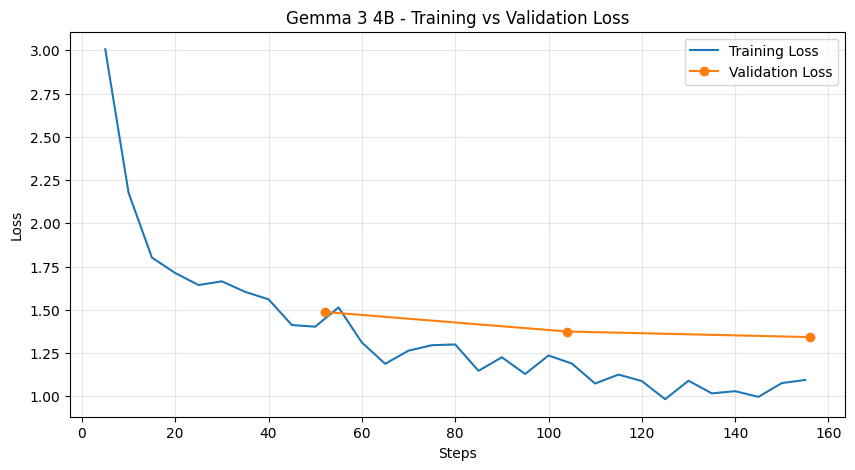

In [26]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(trainer.state.log_history)

train = history_df.dropna(subset=["loss"])
valid = history_df.dropna(subset=["eval_loss"])

plt.figure(figsize=(10, 5))

plt.plot(train["step"], train["loss"], label="Training Loss")
plt.plot(valid["step"], valid["eval_loss"],
         marker="o", label="Validation Loss")

plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Gemma 3 4B - Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
model.save_pretrained("gemma3-khmer-lora")
tokenizer.save_pretrained("gemma3-khmer-lora")

print("LoRA adapter saved!")

Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-lora/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-lora.


LoRA adapter saved!


In [28]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
import os

save_path = "/content/drive/MyDrive/gemma3-khmer-lora"

os.makedirs(save_path, exist_ok=True)

# Save trained LoRA adapters
model.save_pretrained(save_path)

# Save tokenizer
tokenizer.save_pretrained(save_path)

print("✅ Gemma 3 Khmer LoRA saved successfully!")
print("Location:", save_path)
print("Files:", os.listdir(save_path))

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/gemma3-khmer-lora/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/gemma3-khmer-lora.


✅ Gemma 3 Khmer LoRA saved successfully!
Location: /content/drive/MyDrive/gemma3-khmer-lora
Files: ['README.md', 'adapter_model.safetensors', 'adapter_config.json', 'chat_template.jinja', 'tokenizer_config.json', 'tokenizer.json', 'tokenizer.model', 'processor_config.json']


In [30]:

import torch

def ask_gemma(question, max_new_tokens=256):

    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )

    return answer.strip()


In [31]:
questions = [
    "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?",
    "តើអតិថិជនត្រូវមានអាយុប៉ុន្មានដើម្បីស្នើសុំឥណទាន?",
    "តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?"
]

for i, question in enumerate(questions, 1):

    print("=" * 70)
    print(f"QUESTION {i}:")
    print(question)

    print("\nMODEL ANSWER:")
    print(ask_gemma(question))
    print()

QUESTION 1:
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?

MODEL ANSWER:
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាប័ណ្ណអេឡិចត្រូនិក ដែលផ្តល់ជូនអតិថិជន ដើម្បីប្រើប្រាស់ក្នុងការទូទាត់ថ្លៃទំនិញ និងសេវាកម្មផ្សេងៗ ក្នុងប្រទេសកម្ពុជា ដោយមិនចាំបាច់ប្រើប្រាស់ប្រាក់ដុល្លារអាមេរិក ឬប្រាក់រៀល។ ប័ណ្ណនេះអាចប្រើប្រាស់បានគ្រប់ទីកន្លែងដែលមានម៉ាស៊ីនឆូតកាត ឬម៉ាស៊ីនអេធីអឹម។ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មិនមានកាលកំណត់ប្រើប្រាស់ ហើយអាចប្រើប្រាស់បានរហូតដល់ ៥ឆ្នាំ។ ប័ណ្ណនេះអាចប្រើប្រាស់បានគ្រប់ទីកន្លែងដែលមានម៉ាស៊ីនឆូតកាត ឬម៉ាស៊ីនអេធីអឹម។ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្ម្តា មិនមានកាលកំណត់ប្រើប្រាស់ ហើយអាចប្រើប្រាស់បានរហូតដល់

QUESTION 2:
តើអតិថិជនត្រូវមានអាយុប៉ុន្មានដើម្បីស្នើសុំឥណទាន?

MODEL ANSWER:
អតិថិជនត្រូវមានអាយុយ៉ាងតិច ១៨ ឆ្នាំ សម្រាប់ស្នើសុំឥណទាន។ សម្រាប់អតិថិជនដែលជាបុគ្គលិកក្រុមហ៊ុន ត្រូវមានអាយុយ៉ាងតិច ២១ ឆ្នាំ សម្រាប់ស្នើសុំឥណទាន។ សម្រាប់អតិថិជនដែលជាអ្នកនិស្សិត ត្រូវមានអាយុយ៉ាងតិច ២១ ឆ្នាំ សម្រាប់ស្នើសុំឥណទាន។ សម្រាប់អតិថិជនដែលជាអ្នកនិស្សិត ត្រូវមានអាយុយ៉ាងតិច ២៣ ឆ្នាំ សម្រាប់ស្នើសុំឥណទាន។